# Lab 1 – Partie 2 : Classification multi-classes avec un DNN/MLP (PyTorch)
**Dataset :** Machine Predictive Maintenance Classification (`shivamb/machine-predictive-maintenance-classification`, 10 000 lignes)

**Tâche :** prédire le **type de panne** (`Failure Type`) d'une machine à partir de capteurs (température, vitesse de rotation, couple, usure de l'outil, type de produit).

Plan : pré-traitement → EDA → split + standardisation → augmentation (SMOTE) → MLP → GridSearch → courbes → métriques → régularisation → synthèse.

In [1]:
# !pip -q install imbalanced-learn kagglehub   # (Colab/Kaggle) si nécessaire
import os, glob, copy, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display

import torch, torch.nn as nn
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.base import BaseEstimator, ClassifierMixin
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix)

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
SEED = 42
np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
QUICK = os.environ.get("QUICK_RUN", "0") == "1"
print("Device :", device, "| QUICK :", QUICK)

os.makedirs("figures", exist_ok=True); os.makedirs("results", exist_ok=True)
def save_fig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}.png", dpi=130, bbox_inches="tight"); plt.show()

Device : cpu | QUICK : False


## 1. Chargement et pré-traitement (nettoyage)

In [2]:
def locate_csv():
    for d in [os.environ.get("DATA_DIR", ""), "/kaggle/input/machine-predictive-maintenance-classification", ".", "data", "/content"]:
        if d and os.path.isdir(d):
            for f in glob.glob(os.path.join(d, "*.csv")):
                if "predictive_maintenance" in os.path.basename(f).lower() or "ai4i" in os.path.basename(f).lower():
                    return f
    import kagglehub
    d = kagglehub.dataset_download("shivamb/machine-predictive-maintenance-classification")
    return glob.glob(os.path.join(d, "*.csv"))[0]

raw = pd.read_csv(locate_csv())
display(raw.head()); raw.info()
print("Valeurs manquantes :", int(raw.isna().sum().sum()), "| doublons :", int(raw.duplicated().sum()))

Using Colab cache for faster access to the 'machine-predictive-maintenance-classification' dataset.


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 10 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Target                   10000 non-null  int64  
 9   Failure Type             10000 non-null  object 
dtypes: float64(3), int64(4), object(3)
memory usage: 781.4+ KB
Valeurs manquantes : 0 | doublons : 0


In [3]:
df = raw.copy()
for old, new in [(" [K]", ""), (" [rpm]", ""), (" [Nm]", ""), (" [min]", ""), (" ", "_")]:
    df.columns = [c.replace(old, new) for c in df.columns]
print(list(df.columns))

# Cohérence entre Target (0/1) et Failure_Type
display(pd.crosstab(df["Failure_Type"], df["Target"]))

['UDI', 'Product_ID', 'Type', 'Air_temperature', 'Process_temperature', 'Rotational_speed', 'Torque', 'Tool_wear', 'Target', 'Failure_Type']


Target,0,1
Failure_Type,,
Heat Dissipation Failure,0,112
No Failure,9643,9
Overstrain Failure,0,78
Power Failure,0,95
Random Failures,18,0
Tool Wear Failure,0,45


In [4]:
# Lignes incohérentes : Target=0 mais une panne est indiquée (ex. 'Random Failures'), ou Target=1 sans panne.
# Ces étiquettes sont suspectes (bruit) : on les supprime (attention : cela supprime la classe 'Random Failures', ~18 lignes).
DROP_INCONSISTENT = True
inconsistent = ((df["Target"] == 0) & (df["Failure_Type"] != "No Failure")) | ((df["Target"] == 1) & (df["Failure_Type"] == "No Failure"))
print("Lignes incohérentes :", int(inconsistent.sum()))
if DROP_INCONSISTENT: df = df[~inconsistent].reset_index(drop=True)

# Détection d'outliers (IQR) – on les inspecte mais on les garde : ce sont des mesures physiques plausibles, liées aux pannes
num_cols = ["Air_temperature", "Process_temperature", "Rotational_speed", "Torque", "Tool_wear"]
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75); iqr = q3 - q1
print("Outliers IQR par variable :\n", ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum().to_string())

# Feature engineering simple (physique) + encodage de 'Type' (L/M/H)
df["Temp_diff"] = df["Process_temperature"] - df["Air_temperature"]
df["Power"] = df["Torque"] * df["Rotational_speed"] * 2 * np.pi / 60       # puissance mécanique (W)
df = pd.concat([df, pd.get_dummies(df["Type"], prefix="Type", dtype=float)], axis=1)

# 'Target' est supprimée des features (fuite : elle est déduite de Failure_Type) ; UDI et Product_ID sont des identifiants
FEATURES = num_cols + ["Temp_diff", "Power"] + [c for c in df.columns if c.startswith("Type_")]
le = LabelEncoder().fit(df["Failure_Type"]); CLASSES = list(le.classes_); K = len(CLASSES)
X_all, y_all = df[FEATURES].copy(), le.transform(df["Failure_Type"])
print("Classes :", CLASSES, "| features :", FEATURES, "| taille :", X_all.shape)

Lignes incohérentes : 27
Outliers IQR par variable :
 Air_temperature          0
Process_temperature      0
Rotational_speed       418
Torque                  70
Tool_wear                0
Classes : ['Heat Dissipation Failure', 'No Failure', 'Overstrain Failure', 'Power Failure', 'Tool Wear Failure'] | features : ['Air_temperature', 'Process_temperature', 'Rotational_speed', 'Torque', 'Tool_wear', 'Temp_diff', 'Power', 'Type_H', 'Type_L', 'Type_M'] | taille : (9973, 10)


## 2. Analyse exploratoire (EDA)

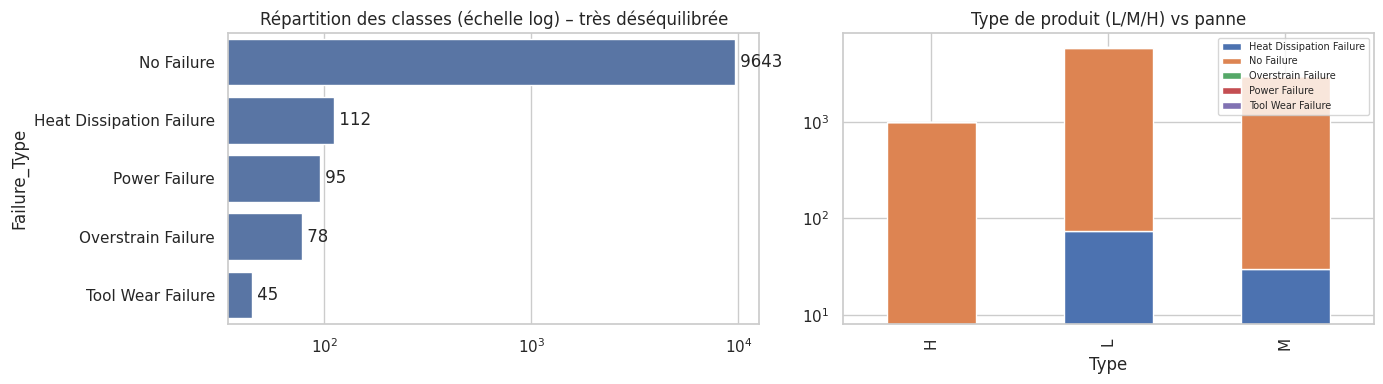

Failure_Type
No Failure                  96.69
Heat Dissipation Failure     1.12
Power Failure                0.95
Overstrain Failure           0.78
Tool Wear Failure            0.45


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
vc = df["Failure_Type"].value_counts()
sns.barplot(x=vc.values, y=vc.index, ax=axes[0]); axes[0].set_xscale("log"); axes[0].set_title("Répartition des classes (échelle log) – très déséquilibrée")
for i, v in enumerate(vc.values): axes[0].text(v, i, f" {v}", va="center")
pd.crosstab(df["Type"], df["Failure_Type"]).plot(kind="bar", stacked=True, ax=axes[1], legend=False); axes[1].set_title("Type de produit (L/M/H) vs panne"); axes[1].set_yscale("log")
axes[1].legend(fontsize=7, loc="upper right")
save_fig("p2_eda_classes")
print((vc / len(df) * 100).round(2).to_string())

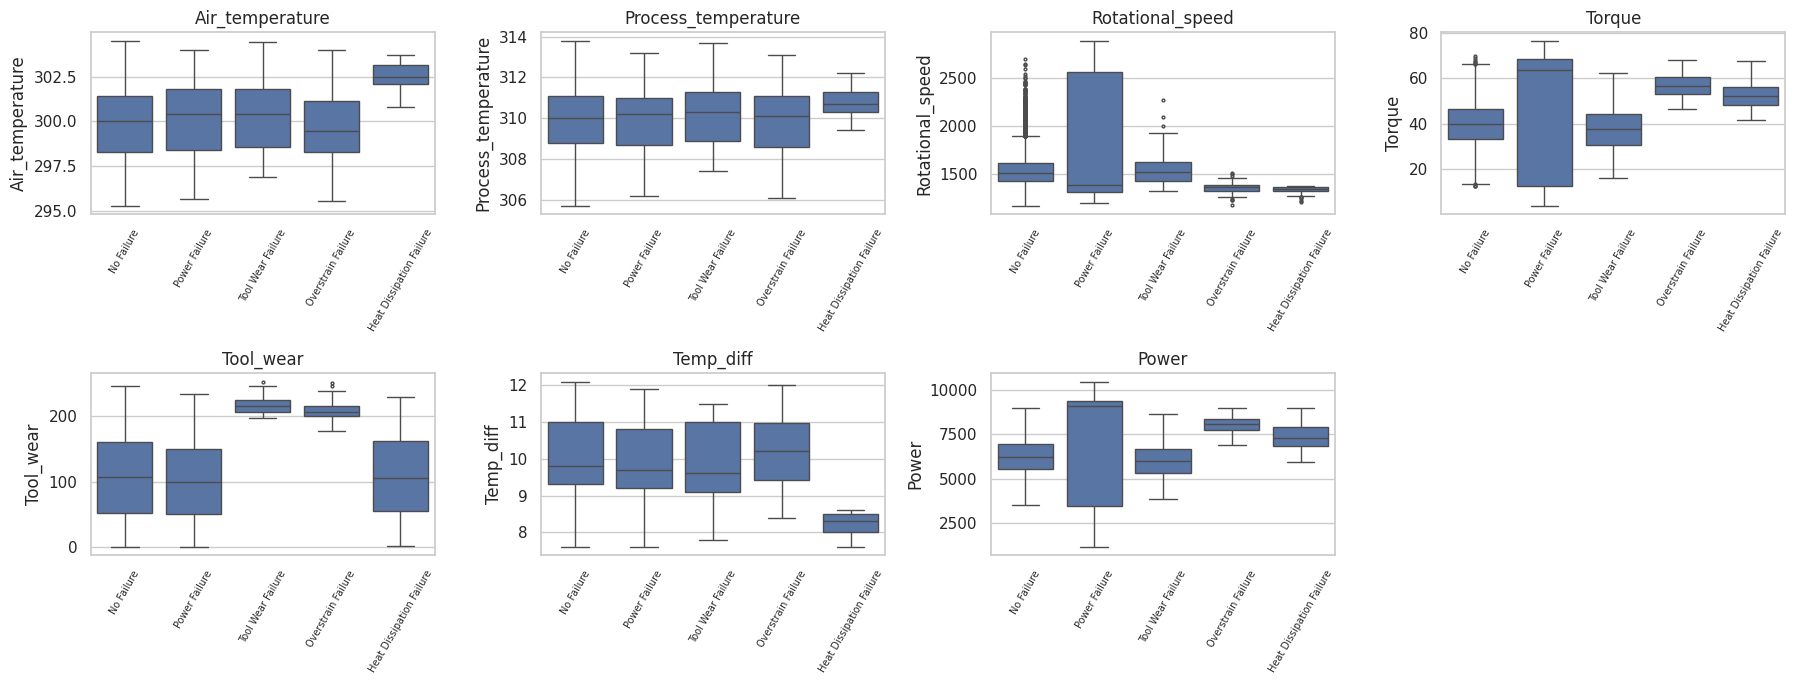

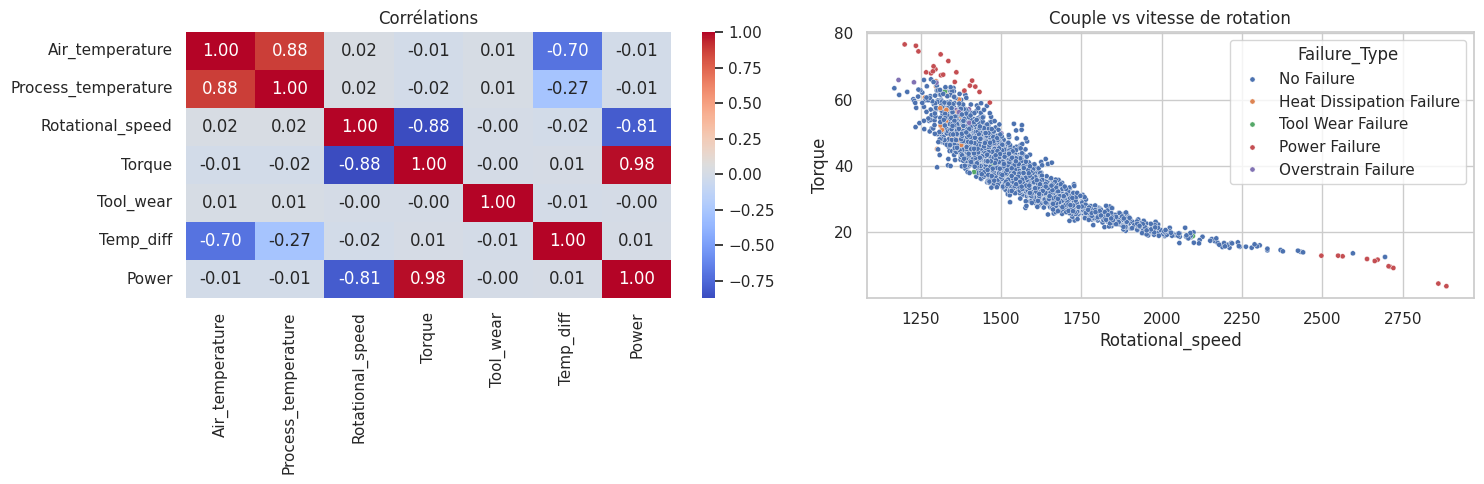

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7)); axes = axes.ravel()
for ax, c in zip(axes, num_cols + ["Temp_diff", "Power"]):
    sns.boxplot(data=df, x="Failure_Type", y=c, ax=ax, fliersize=2); ax.set_title(c); ax.set_xlabel(""); ax.tick_params(axis="x", rotation=60, labelsize=7)
axes[-1].axis("off")
save_fig("p2_eda_boxplots")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(df[num_cols + ["Temp_diff", "Power"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[0]); axes[0].set_title("Corrélations")
sns.scatterplot(data=df.sample(min(3000, len(df)), random_state=SEED), x="Rotational_speed", y="Torque", hue="Failure_Type", s=14, ax=axes[1]); axes[1].set_title("Couple vs vitesse de rotation")
save_fig("p2_eda_correlation_scatter")

**Observations EDA (à compléter) :**
- Classe `No Failure` ≈ 97 % ; les 4 types de pannes restants sont rares (≈ 0.5 – 1.2 % chacun) → accuracy seule trompeuse ; on suivra **F1-macro** et la sensibilité par classe.
- Variables fortement liées à des pannes : `Tool_wear` (usure), `Torque`/`Rotational_speed` (surcharge, puissance), `Temp_diff` (dissipation thermique). `Air_temperature` et `Process_temperature` sont très corrélées entre elles.

## 3. Split, standardisation et augmentation de données (SMOTE)
Ordre rigoureux pour **éviter toute fuite de données** : split stratifié → standardisation ajustée sur le train → SMOTE **uniquement sur le train** (jamais sur validation/test).

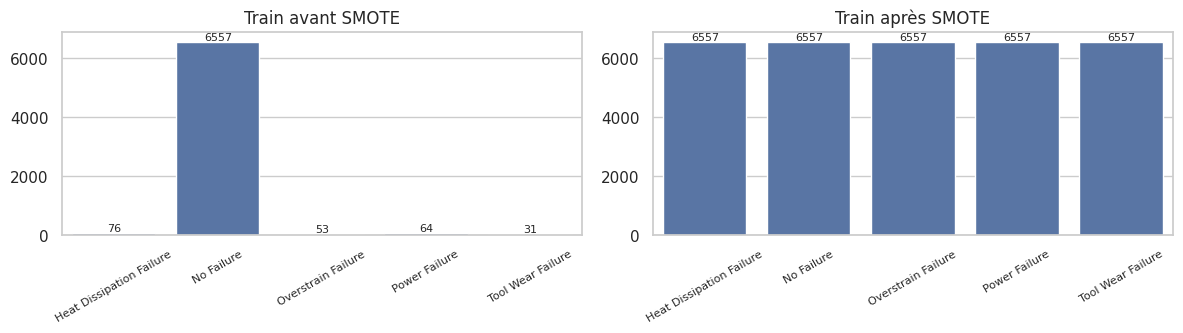

Taille train : 6781 -> 32785 | validation : 1197 | test : 1995


In [7]:
X_trv, X_te, y_trv, y_te = train_test_split(X_all, y_all, test_size=0.20, stratify=y_all, random_state=SEED)     # train+val / test
X_tr, X_va, y_tr, y_va = train_test_split(X_trv, y_trv, test_size=0.15, stratify=y_trv, random_state=SEED)      # train / validation (early stopping)

scaler = StandardScaler().fit(X_tr)
Xs_tr, Xs_va, Xs_te = scaler.transform(X_tr), scaler.transform(X_va), scaler.transform(X_te)

smote = SMOTE(random_state=SEED, k_neighbors=3)       # interpole entre voisins de la même classe
Xs_tr_res, y_tr_res = smote.fit_resample(Xs_tr, y_tr)

before, after = np.bincount(y_tr, minlength=K), np.bincount(y_tr_res, minlength=K)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=False)
for ax, cnt, t in zip(axes, [before, after], ["Train avant SMOTE", "Train après SMOTE"]):
    sns.barplot(x=CLASSES, y=cnt, ax=ax); ax.set_title(t); ax.tick_params(axis="x", rotation=30, labelsize=8)
    for i, v in enumerate(cnt): ax.text(i, v, str(v), ha="center", va="bottom", fontsize=8)
save_fig("p2_smote_balance")
print("Taille train :", len(y_tr), "->", len(y_tr_res), "| validation :", len(y_va), "| test :", len(y_te))

In [8]:
T = lambda a, dt=torch.float32: torch.tensor(np.asarray(a), dtype=dt, device=device)
# data = (train rééchantillonné, validation, test, train original) : le train original sert aux métriques « train » non biaisées par SMOTE
data = dict(Xtr=T(Xs_tr_res), ytr=T(y_tr_res, torch.long), Xva=T(Xs_va), yva=T(y_va, torch.long),
            Xte=T(Xs_te), yte=T(y_te, torch.long), Xtr0=T(Xs_tr), ytr0=T(y_tr, torch.long))

## 4. Architecture MLP multi-classes (PyTorch)

In [9]:
class MLP(nn.Module):
    def __init__(self, in_dim, out_dim, hidden=(64, 32), dropout=0.0, batchnorm=False):
        super().__init__()
        layers, d = [], in_dim
        for h in hidden:
            layers.append(nn.Linear(d, h))
            if batchnorm: layers.append(nn.BatchNorm1d(h))
            layers.append(nn.ReLU())
            if dropout > 0: layers.append(nn.Dropout(dropout))
            d = h
        layers.append(nn.Linear(d, out_dim))        # logits ; softmax est inclus dans CrossEntropyLoss
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

def make_optimizer(name, params, lr, weight_decay=0.0):
    name = name.lower()
    if name == "adam":    return torch.optim.Adam(params, lr=lr, weight_decay=weight_decay)
    if name == "adamw":   return torch.optim.AdamW(params, lr=lr, weight_decay=weight_decay)
    if name == "rmsprop": return torch.optim.RMSprop(params, lr=lr, weight_decay=weight_decay)
    if name == "sgd":     return torch.optim.SGD(params, lr=lr, momentum=0.9, weight_decay=weight_decay)
    raise ValueError(name)

@torch.no_grad()
def evaluate(model, X, y, loss_fn):
    model.eval(); out = model(X)
    return loss_fn(out, y).item(), (out.argmax(1) == y).float().mean().item()

def train_model(model, d, lr=1e-3, epochs=30, optimizer="adam", batch_size=512,
                weight_decay=0.0, l1=0.0, patience=None, verbose=True):
    model.to(device); loss_fn = nn.CrossEntropyLoss()
    opt = make_optimizer(optimizer, model.parameters(), lr, weight_decay)
    hist = {k: [] for k in ["train_loss", "val_loss", "test_loss", "train_acc", "val_acc", "test_acc"]}
    best_val, best_state, wait, n = float("inf"), None, 0, len(d["Xtr"])
    for ep in range(1, epochs + 1):
        model.train(); perm = torch.randperm(n, device=device)
        for i in range(0, n, batch_size):
            idx = perm[i:i + batch_size]
            if len(idx) < 2: continue
            opt.zero_grad(); loss = loss_fn(model(d["Xtr"][idx]), d["ytr"][idx])
            if l1 > 0: loss = loss + l1 * sum(p.abs().sum() for p in model.parameters() if p.dim() > 1)
            loss.backward(); opt.step()
        for nm in ["tr", "va", "te"]:
            l, a = evaluate(model, d["X" + nm], d["y" + nm], loss_fn)
            key = {"tr": "train", "va": "val", "te": "test"}[nm]; hist[key + "_loss"].append(l); hist[key + "_acc"].append(a)
        if verbose and (ep == 1 or ep % 5 == 0):
            print(f"ep {ep:3d} | loss train {hist['train_loss'][-1]:.4f} test {hist['test_loss'][-1]:.4f} | acc train {hist['train_acc'][-1]:.3f} test {hist['test_acc'][-1]:.3f}")
        if patience:
            if hist["val_loss"][-1] < best_val - 1e-6:
                best_val, best_state, wait = hist["val_loss"][-1], copy.deepcopy(model.state_dict()), 0
            else:
                wait += 1
                if wait >= patience: print(f"Early stopping à l'epoch {ep}"); break
    if best_state is not None: model.load_state_dict(best_state)
    return model, hist

def plot_history(hist, title, fname=None):
    ep = range(1, len(hist["train_loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(ep, hist["train_loss"], label="train (SMOTE)"); axes[0].plot(ep, hist["test_loss"], label="test")
    axes[0].set_title("Loss / Epochs"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy"); axes[0].legend()
    axes[1].plot(ep, hist["train_acc"], label="train (SMOTE)"); axes[1].plot(ep, hist["test_acc"], label="test")
    axes[1].set_title("Accuracy / Epochs"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    fig.suptitle(title); save_fig(fname) if fname else plt.show()

@torch.no_grad()
def predict(model, X):
    model.eval(); return model(X).argmax(1).cpu().numpy()

## 5. GridSearch (sklearn)
Le `GridSearchCV` encapsule **StandardScaler → SMOTE → MLP** dans un `imblearn.Pipeline` : à chaque pli, le scaler et SMOTE sont ajustés uniquement sur les données d'entraînement du pli (pas de fuite). Métrique de sélection : **F1-macro** (adaptée au déséquilibre).

In [10]:
class TorchClassifier(BaseEstimator, ClassifierMixin):
    def __init__(self, hidden=(64, 32), lr=1e-3, epochs=20, optimizer="adam", batch_size=512, dropout=0.0, weight_decay=0.0):
        self.hidden, self.lr, self.epochs, self.optimizer = hidden, lr, epochs, optimizer
        self.batch_size, self.dropout, self.weight_decay = batch_size, dropout, weight_decay
    def fit(self, X, y):
        torch.manual_seed(SEED)
        self.classes_ = np.unique(y); yi = np.searchsorted(self.classes_, y)
        X = torch.tensor(np.asarray(X, dtype=np.float32), device=device); yi = torch.tensor(yi, dtype=torch.long, device=device)
        self.model_ = MLP(X.shape[1], len(self.classes_), self.hidden, self.dropout).to(device)
        opt = make_optimizer(self.optimizer, self.model_.parameters(), self.lr, self.weight_decay); loss_fn = nn.CrossEntropyLoss()
        for _ in range(self.epochs):
            self.model_.train(); perm = torch.randperm(len(X), device=device)
            for i in range(0, len(X), self.batch_size):
                idx = perm[i:i + self.batch_size]
                if len(idx) < 2: continue
                opt.zero_grad(); loss_fn(self.model_(X[idx]), yi[idx]).backward(); opt.step()
        return self
    @torch.no_grad()
    def predict(self, X):
        self.model_.eval()
        out = self.model_(torch.tensor(np.asarray(X, dtype=np.float32), device=device)).argmax(1).cpu().numpy()
        return self.classes_[out]

pipe = ImbPipeline([("scaler", StandardScaler()), ("smote", SMOTE(random_state=SEED, k_neighbors=3)), ("clf", TorchClassifier())])
param_grid = {
    "clf__hidden": [(64, 32), (128, 64), (128, 64, 32)],
    "clf__lr": [1e-3, 1e-2],
    "clf__optimizer": ["adam", "rmsprop", "sgd"],
    "clf__epochs": [15, 30],
    "clf__batch_size": [512],
}
if QUICK: param_grid.update({"clf__hidden": [(32,), (64, 32)], "clf__optimizer": ["adam"], "clf__epochs": [3], "clf__lr": [1e-2]})

gs = GridSearchCV(pipe, param_grid, cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="f1_macro", n_jobs=1, refit=False, verbose=1)
gs.fit(X_trv.values, y_trv)
res = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
display(res[["param_clf__hidden", "param_clf__lr", "param_clf__optimizer", "param_clf__epochs", "mean_test_score", "std_test_score", "rank_test_score"]].head(10))
res.to_csv("results/p2_gridsearch.csv", index=False)
best = {k.replace("clf__", ""): v for k, v in gs.best_params_.items()}
print("Meilleurs hyper-paramètres :", best)

Fitting 3 folds for each of 36 candidates, totalling 108 fits


,param_clf__hidden,param_clf__lr,param_clf__optimizer,param_clf__epochs,mean_test_score,std_test_score,rank_test_score
27,"(128, 64)",0.010,adam,30,0.677403,0.020828,1
33,"(128, 64, 32)",0.010,adam,30,0.672438,0.013724,2
21,"(64, 32)",0.010,adam,30,0.665008,0.029545,3
31,"(128, 64, 32)",0.001,rmsprop,30,0.664447,0.029559,4
15,"(128, 64, 32)",0.010,adam,15,0.642678,0.010143,5
24,"(128, 64)",0.001,adam,30,0.640736,0.006794,6
30,"(128, 64, 32)",0.001,adam,30,0.637672,0.011755,7
9,"(128, 64)",0.010,adam,15,0.631601,0.028816,8
16,"(128, 64, 32)",0.010,rmsprop,15,0.630881,0.020536,9
25,"(128, 64)",0.001,rmsprop,30,0.626897,0.007206,10


Meilleurs hyper-paramètres : {'batch_size': 512, 'epochs': 30, 'hidden': (128, 64), 'lr': 0.01, 'optimizer': 'adam'}


## 6. Modèle 1 (meilleurs hyper-paramètres) : courbes Loss/Epochs et Accuracy/Epochs

ep   1 | loss train 0.1198 test 0.1597 | acc train 0.961 test 0.938
ep   5 | loss train 0.3235 test 0.1107 | acc train 0.864 test 0.974
ep  10 | loss train 0.0256 test 0.2059 | acc train 0.992 test 0.948
ep  15 | loss train 0.0145 test 0.1703 | acc train 0.997 test 0.965
ep  20 | loss train 0.0132 test 0.2081 | acc train 0.996 test 0.964
ep  25 | loss train 0.0207 test 0.2801 | acc train 0.994 test 0.954
ep  30 | loss train 0.0157 test 0.2678 | acc train 0.996 test 0.963
ep  35 | loss train 0.0229 test 0.3053 | acc train 0.995 test 0.963
ep  40 | loss train 0.0075 test 0.2478 | acc train 0.998 test 0.971


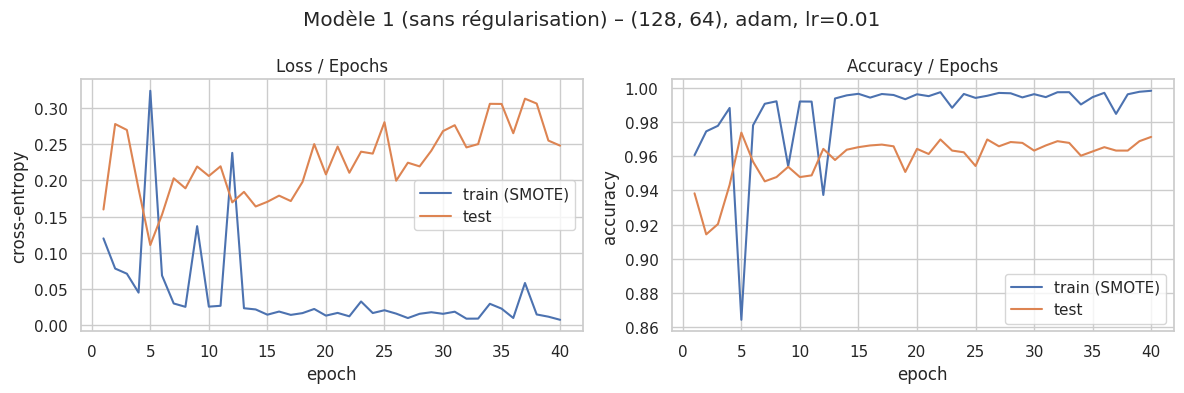

In [11]:
EPOCHS = 3 if QUICK else max(best["epochs"], 40)
torch.manual_seed(SEED)
model1 = MLP(len(FEATURES), K, best["hidden"])
model1, hist1 = train_model(model1, data, lr=best["lr"], epochs=EPOCHS, optimizer=best["optimizer"], batch_size=best["batch_size"])
plot_history(hist1, f"Modèle 1 (sans régularisation) – {best['hidden']}, {best['optimizer']}, lr={best['lr']}", "p2_model1_curves")

**Interprétation (à adapter à vos courbes) :**
- *Loss/Epochs* : la loss d'entraînement (données SMOTE) baisse régulièrement ; une loss de test qui remonte après un minimum indique du surapprentissage des échantillons synthétiques.
- *Accuracy/Epochs* : l'accuracy de test est **inférieure** à celle du train rééchantillonné et inférieure à ce qu'obtiendrait un modèle « tout No Failure » (≈ 97 %) : normal, SMOTE déplace la frontière de décision vers les classes rares (compromis précision/sensibilité). Il faut donc juger sur le F1-macro et la sensibilité par classe, pas sur l'accuracy seule.

## 7. Métriques : accuracy, sensibilité (recall), précision, F1, spécificité – train et test

,accuracy,precision (macro),sensibilité/recall (macro),F1 (macro),F1 (pondéré)
jeu,,,,,
train (original),0.9926,0.8527,0.9954,0.9036,0.9936
test,0.9714,0.6260,0.7230,0.6657,0.9748



--- Métriques par classe : train (original) ---


,sensibilité,spécificité,précision,F1,support
Heat Dissipation Failure,1.000,1.000,0.974,0.987,76
No Failure,0.993,0.996,1.000,0.996,6557
Overstrain Failure,1.000,0.999,0.914,0.955,53
Power Failure,0.984,0.999,0.913,0.947,64
Tool Wear Failure,1.000,0.995,0.463,0.633,31



--- Métriques par classe : test ---


,sensibilité,spécificité,précision,F1,support
Heat Dissipation Failure,0.864,0.996,0.731,0.792,22
No Failure,0.980,0.758,0.992,0.986,1929
Overstrain Failure,0.812,0.996,0.650,0.722,16
Power Failure,0.737,0.996,0.667,0.700,19
Tool Wear Failure,0.222,0.990,0.091,0.129,9


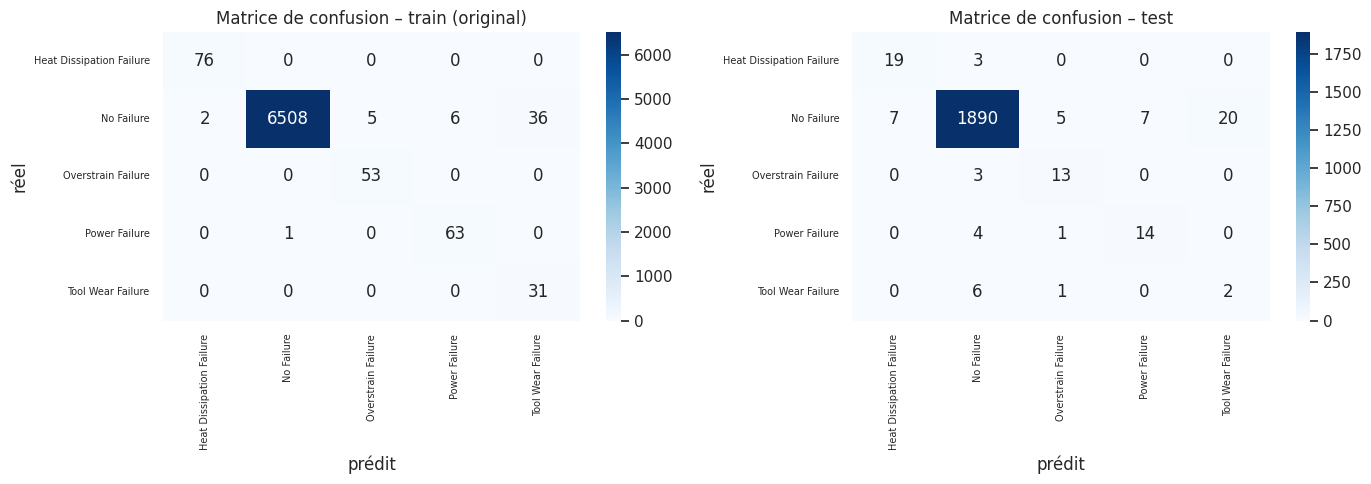

In [12]:
def summary_metrics(model, name, X, y):
    yp, yt = predict(model, X), y.cpu().numpy()
    return {"jeu": name, "accuracy": accuracy_score(yt, yp), "precision (macro)": precision_score(yt, yp, average="macro", zero_division=0),
            "sensibilité/recall (macro)": recall_score(yt, yp, average="macro", zero_division=0),
            "F1 (macro)": f1_score(yt, yp, average="macro", zero_division=0), "F1 (pondéré)": f1_score(yt, yp, average="weighted", zero_division=0)}

def per_class_table(model, X, y):
    yp, yt = predict(model, X), y.cpu().numpy()
    cm = confusion_matrix(yt, yp, labels=range(K)); TP = np.diag(cm); FN = cm.sum(1) - TP; FP = cm.sum(0) - TP; TN = cm.sum() - (TP + FN + FP)
    return pd.DataFrame({"sensibilité": TP / np.maximum(TP + FN, 1), "spécificité": TN / np.maximum(TN + FP, 1),
                         "précision": TP / np.maximum(TP + FP, 1), "F1": 2 * TP / np.maximum(2 * TP + FP + FN, 1), "support": cm.sum(1)}, index=CLASSES)

sets = {"train (original)": (data["Xtr0"], data["ytr0"]), "test": (data["Xte"], data["yte"])}
metrics1 = pd.DataFrame([summary_metrics(model1, n, *s) for n, s in sets.items()]).set_index("jeu"); display(metrics1.round(4))
for n, s in sets.items():
    print(f"\n--- Métriques par classe : {n} ---"); display(per_class_table(model1, *s).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (n, s) in zip(axes, sets.items()):
    cm = confusion_matrix(s[1].cpu().numpy(), predict(model1, s[0]), labels=range(K))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=ax); ax.set_title(f"Matrice de confusion – {n}")
    ax.set_xlabel("prédit"); ax.set_ylabel("réel"); ax.tick_params(labelsize=7)
save_fig("p2_model1_confusion")

## 8. Régularisation et comparaison avec le modèle 1
Dropout, L2 (*weight decay*), L1, BatchNorm, Early stopping et combinaisons, avec la même architecture/optimiseur/lr que le modèle 1.

In [13]:
configs = {
    "Modèle 1 (aucune)":        dict(),
    "Dropout 0.3":              dict(dropout=0.3),
    "L2 (wd=1e-3)":             dict(weight_decay=1e-3),
    "L1 (1e-5)":                dict(l1=1e-5),
    "BatchNorm":                dict(batchnorm=True),
    "Early stopping (p=8)":     dict(patience=8),
    "Dropout+L2+EarlyStop":     dict(dropout=0.3, weight_decay=1e-3, patience=8),
    "BN+Dropout+L2+EarlyStop":  dict(batchnorm=True, dropout=0.3, weight_decay=1e-3, patience=8),
}
hists, models, rows = {}, {}, []
for name, cfg in configs.items():
    print(f"\n=== {name} ===")
    torch.manual_seed(SEED)
    m = MLP(len(FEATURES), K, best["hidden"], dropout=cfg.get("dropout", 0.0), batchnorm=cfg.get("batchnorm", False))
    m, h = train_model(m, data, lr=best["lr"], epochs=EPOCHS, optimizer=best["optimizer"], batch_size=best["batch_size"],
                       weight_decay=cfg.get("weight_decay", 0.0), l1=cfg.get("l1", 0.0), patience=cfg.get("patience"), verbose=False)
    hists[name], models[name] = h, m
    mtr, mte = summary_metrics(m, "train", data["Xtr0"], data["ytr0"]), summary_metrics(m, "test", data["Xte"], data["yte"])
    rows.append({"modèle": name, "epochs": len(h["train_loss"]), "acc train": mtr["accuracy"], "acc test": mte["accuracy"],
                 "F1-macro train": mtr["F1 (macro)"], "F1-macro test": mte["F1 (macro)"],
                 "sensibilité-macro test": mte["sensibilité/recall (macro)"], "écart F1 (train-test)": mtr["F1 (macro)"] - mte["F1 (macro)"]})
comp = pd.DataFrame(rows).set_index("modèle"); comp.to_csv("results/p2_regularization_comparison.csv"); display(comp.round(4))


=== Modèle 1 (aucune) ===

=== Dropout 0.3 ===

=== L2 (wd=1e-3) ===

=== L1 (1e-5) ===

=== BatchNorm ===

=== Early stopping (p=8) ===
Early stopping à l'epoch 13

=== Dropout+L2+EarlyStop ===
Early stopping à l'epoch 16

=== BN+Dropout+L2+EarlyStop ===
Early stopping à l'epoch 13


,epochs,acc train,acc test,F1-macro train,F1-macro test,sensibilité-macro test,écart F1 (train-test)
modèle,,,,,,,
Modèle 1 (aucune),40,0.9926,0.9714,0.9036,0.6657,0.7230,0.2379
Dropout 0.3,40,0.9679,0.9539,0.7450,0.6512,0.8121,0.0938
L2 (wd=1e-3),40,0.9617,0.9489,0.7020,0.6214,0.8235,0.0806
L1 (1e-5),40,0.9900,0.9684,0.8789,0.6654,0.7341,0.2135
BatchNorm,40,0.9677,0.9464,0.7521,0.6246,0.8463,0.1275
Early stopping (p=8),13,0.9844,0.9739,0.7817,0.6255,0.6304,0.1562
Dropout+L2+EarlyStop,16,0.9451,0.9363,0.6503,0.5938,0.8500,0.0565
BN+Dropout+L2+EarlyStop,13,0.9406,0.9293,0.6381,0.5996,0.8775,0.0386


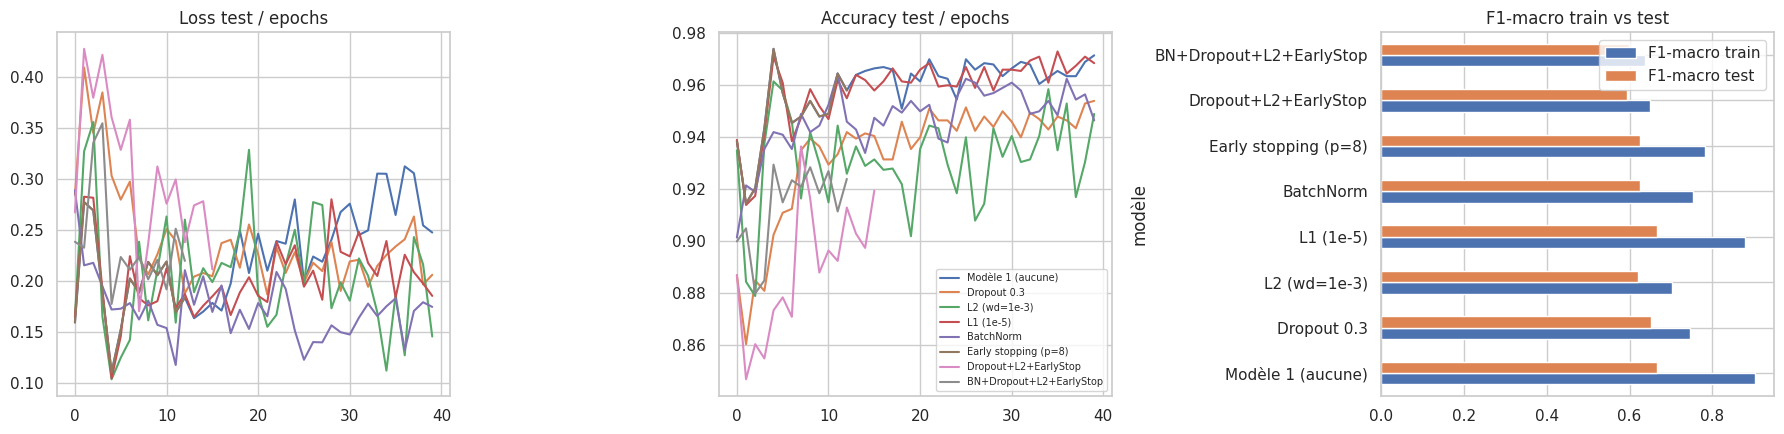

Meilleur modèle (F1-macro test) : Modèle 1 (aucune)


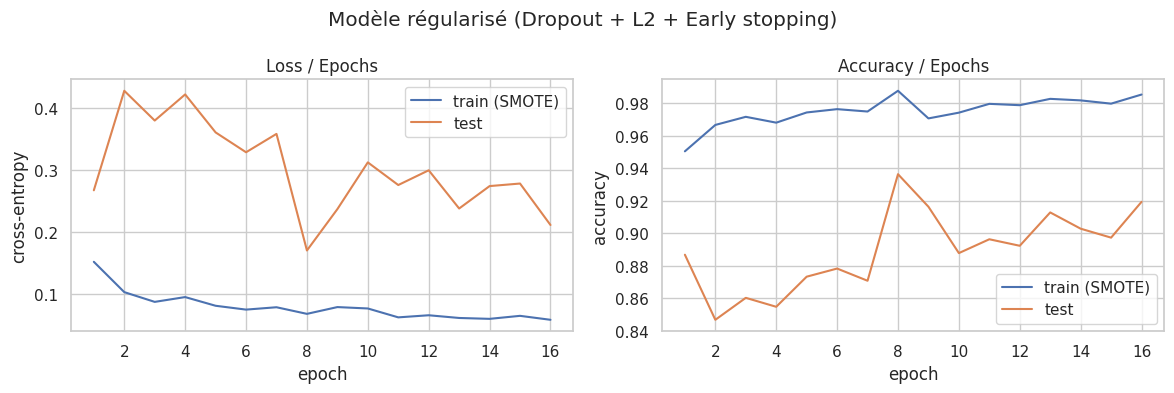


--- Détail par classe (test) : modèle 1 vs meilleur ---


,sensibilité,spécificité,précision,F1,support
Heat Dissipation Failure,0.864,0.996,0.731,0.792,22
No Failure,0.980,0.758,0.992,0.986,1929
Overstrain Failure,0.812,0.996,0.650,0.722,16
Power Failure,0.737,0.996,0.667,0.700,19
Tool Wear Failure,0.222,0.990,0.091,0.129,9


,sensibilité,spécificité,précision,F1,support
Heat Dissipation Failure,0.864,0.996,0.731,0.792,22
No Failure,0.980,0.758,0.992,0.986,1929
Overstrain Failure,0.812,0.996,0.650,0.722,16
Power Failure,0.737,0.996,0.667,0.700,19
Tool Wear Failure,0.222,0.990,0.091,0.129,9


In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for name, h in hists.items():
    axes[0].plot(h["test_loss"], label=name); axes[1].plot(h["test_acc"], label=name)
axes[0].set_title("Loss test / epochs"); axes[1].set_title("Accuracy test / epochs"); axes[1].legend(fontsize=7)
comp[["F1-macro train", "F1-macro test"]].plot(kind="barh", ax=axes[2], title="F1-macro train vs test")
save_fig("p2_regularization_comparison")

best_name = comp["F1-macro test"].idxmax(); print("Meilleur modèle (F1-macro test) :", best_name)
plot_history(hists["Dropout+L2+EarlyStop"], "Modèle régularisé (Dropout + L2 + Early stopping)", "p2_model2_curves")
print("\n--- Détail par classe (test) : modèle 1 vs meilleur ---")
display(per_class_table(model1, data["Xte"], data["yte"]).round(3)); display(per_class_table(models[best_name], data["Xte"], data["yte"]).round(3))

**Comparaison / conclusion (à adapter à vos résultats) :**
- Comparer `F1-macro test`, `sensibilité-macro test` et `écart F1 (train-test)` entre le modèle 1 et chaque variante.
- Les classes rares (ex. *Tool Wear Failure*) ont très peu d'exemples de test (≈ 9) : les scores par classe sont **bruités**, il faut être prudent dans les conclusions ; une validation croisée ou plusieurs graines améliorerait la fiabilité.
- Dropout/L2/early stopping réduisent généralement l'écart train-test ; l'accuracy peut baisser légèrement tandis que la sensibilité des classes rares augmente.

## 9. Synthèse personnelle (à rédiger)
- **Pipeline** : nettoyage (incohérences Target/Failure Type, suppression de la fuite `Target`) → EDA → split stratifié → standardisation + SMOTE **sur le train uniquement** → MLP PyTorch → GridSearch (Pipeline imblearn, F1-macro) → métriques complètes → régularisation.
- **Ce que j'ai appris** : gérer un fort déséquilibre de classes (SMOTE, métriques adaptées : F1-macro, sensibilité, spécificité), éviter la fuite de données, construire un classifieur multi-classes (logits + CrossEntropyLoss), utiliser GridSearchCV avec PyTorch, et interpréter les effets des régularisations.